# Random Forest : comparer les régions

On teste le même modèle avec **12 régions**, puis avec **7 groupes de régions**.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

## Charger les deux fichiers

- Le premier contient les régions d’origine.
- Le deuxième contient les régions regroupées.

In [ ]:
df = pd.read_csv("../dataset/dataset_musique_region.csv")
df_group = pd.read_csv("../dataset/dataset_musique_region_transforme.csv")

print("Sans regroupement :", df.shape)
print("Avec regroupement :", df_group.shape)

Sans regroupement : (1986, 14)
Avec regroupement : (1986, 16)


## Séparer les données

- `X` : les 13 genres musicaux.
- On garde les mêmes personnes dans le test pour les deux modèles.

In [ ]:
X = df.drop(columns="region")
assert df["region"].equals(df_group["region"])
assert X.equals(df_group[X.columns])

indices_train, indices_test = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=df["region"]
)
X_train = X.loc[indices_train]
X_test = X.loc[indices_test]

print("Entraînement :", len(X_train))
print("Test :", len(X_test))

Entraînement : 1588
Test : 398


## 1. Sans regroupement : 12 régions

On entraîne le Random Forest pour prédire la région d’origine.

In [ ]:
y = df["region"]
y_train = y.loc[indices_train]
y_test = y.loc[indices_test]

modele = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
modele.fit(X_train, y_train)
predictions = modele.predict(X_test)

accuracy_12 = accuracy_score(y_test, predictions)
f1_12 = f1_score(y_test, predictions, average="macro", zero_division=0)
print("Accuracy entraînement :", round(modele.score(X_train, y_train) * 100, 1), "%")
print("Accuracy test :", round(accuracy_12 * 100, 1), "%")
print("F1 macro :", round(f1_12, 3))
print(classification_report(y_test, predictions, zero_division=0))

Accuracy entraînement : 31.2 %
Accuracy test : 21.1 %
F1 macro : 0.073
                            precision    recall  f1-score   support

      Auvergne-Rhône-Alpes       0.15      0.09      0.11        47
   Bourgogne-Franche-Comté       0.25      0.06      0.10        17
                  Bretagne       0.00      0.00      0.00        19
       Centre-Val de Loire       0.00      0.00      0.00        16
                 Grand Est       0.43      0.07      0.13        40
           Hauts-de-France       0.17      0.05      0.08        38
                 Normandie       0.00      0.00      0.00        18
        Nouvelle-Aquitaine       0.09      0.03      0.04        39
                 Occitanie       0.00      0.00      0.00        32
          Pays de la Loire       1.00      0.04      0.08        25
Provence-Alpes-Côte d'Azur       0.00      0.00      0.00        26
             Île-de-France       0.22      0.89      0.35        81

                  accuracy                 

### Matrice de confusion : 12 régions

La diagonale montre les bonnes prédictions.

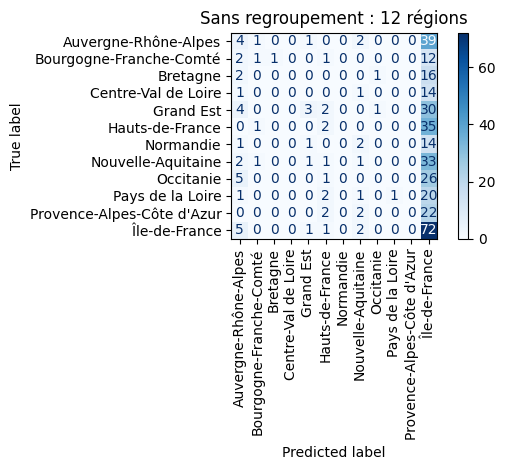

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, xticks_rotation=90, cmap="Blues")
plt.title("Sans regroupement : 12 régions")
plt.tight_layout()
plt.show()

## 2. Avec regroupement : 7 groupes

On entraîne un nouveau Random Forest avec les mêmes paramètres et les mêmes personnes.

In [ ]:
y_group = df_group["region_group"]
y_train_g = y_group.loc[indices_train]
y_test_g = y_group.loc[indices_test]

modele_group = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
modele_group.fit(X_train, y_train_g)
predictions_g = modele_group.predict(X_test)

accuracy_7 = accuracy_score(y_test_g, predictions_g)
f1_7 = f1_score(y_test_g, predictions_g, average="macro", zero_division=0)
print("Accuracy entraînement :", round(modele_group.score(X_train, y_train_g) * 100, 1), "%")
print("Accuracy test :", round(accuracy_7 * 100, 1), "%")
print("F1 macro :", round(f1_7, 3))
print(classification_report(y_test_g, predictions_g, zero_division=0))

Accuracy entraînement : 37.3 %
Accuracy test : 20.9 %
F1 macro : 0.119
                      precision    recall  f1-score   support

Auvergne-Rhône-Alpes       0.10      0.02      0.04        47
              CENTRE       0.22      0.10      0.14        58
           Grand Est       0.33      0.03      0.05        40
          NORD-OUEST       0.18      0.40      0.25        75
  Nouvelle-Aquitaine       0.00      0.00      0.00        39
                 SUD       0.14      0.02      0.03        58
       Île-de-France       0.24      0.54      0.34        81

            accuracy                           0.21       398
           macro avg       0.17      0.16      0.12       398
        weighted avg       0.18      0.21      0.15       398



### Matrice de confusion : 7 groupes

La diagonale montre les bonnes prédictions.

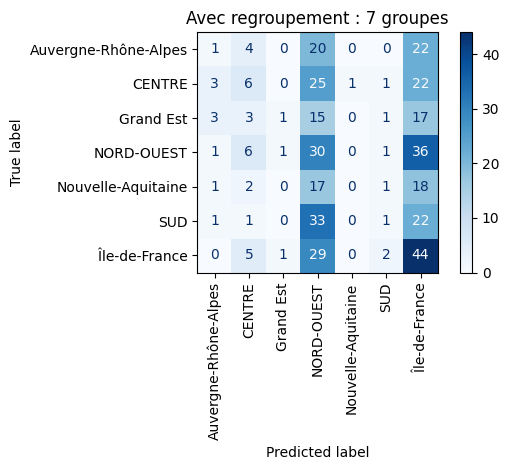

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test_g, predictions_g, xticks_rotation=90, cmap="Blues")
plt.title("Avec regroupement : 7 groupes")
plt.tight_layout()
plt.show()

## 3. Comparer les résultats

- **Accuracy** : part des bonnes prédictions.
- **F1 macro** : score qui donne la même importance à chaque région (+ il est proche de 1, meilleures sont les perf)

In [ ]:
comparaison = pd.DataFrame({
    "Modèle": ["12 régions", "7 groupes"],
    "Accuracy (%)": [round(accuracy_12 * 100, 1), round(accuracy_7 * 100, 1)],
    "F1 macro": [round(f1_12, 3), round(f1_7, 3)]
})
comparaison

,Modèle,Accuracy (%),F1 macro
0,12 régions,21.1,0.073
1,7 groupes,20.9,0.119


In [ ]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")

# Sans regroupement
dummy.fit(X_train, y_train)
print("Référence 12 régions :", dummy.score(X_test, y_test))

# Avec regroupement
dummy.fit(X_train, y_train_g)
print("Référence 7 groupes :", dummy.score(X_test, y_test_g))

Référence 12 régions : 0.20351758793969849
Référence 7 groupes : 0.20351758793969849


## Conclusion

On a testé le Random Forest avec 12 régions, puis avec 7 groupes de régions

- **Sans regroupement :** 21,1 % d'accuracy.
- **Avec regroupement :** 20,9 % d'accuracy.
- Le F1 macro passe de **0,073 à 0,119**.

Le regroupement des régions n'améliore pas l'accuracy, même si le F1 macro augmente un peu.

Les résultats restent très faibles, predire la région d'une personne en fonction de son genres musicaux et sans autres information n'est pas tres efficace